# Customer Churn & Retention Analytics

## Project Overview

This project analyses customer churn in a subscription-based fitness business.

The objective is to identify customer characteristics and engagement patterns associated with churn, understand customer retention behaviour, and build machine learning models to predict customer churn.

### Business Objectives
- Analyse customer subscription patterns.
- Identify factors associated with customer churn.
- Investigate the relationship between customer engagement and retention.
- Perform SQL-based business analysis.
- Develop churn prediction models.
- Provide actionable customer retention recommendations.

### Tools & Technologies
Python | Pandas | NumPy | SQLite | Matplotlib | Scikit-learn | Tableau Public

### Datasets
1. subscriptions.csv
2. usage.csv

# Importing Libraries and Loading Data

In [1]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
import random

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

from google.colab import drive
drive.mount('/content/drive')

base_path = '/content/drive/MyDrive/Peloton_Churn_Project/'

subscriptions = pd.read_csv(base_path + 'subscriptions.csv')
usage = pd.read_csv(base_path + 'usage.csv')

print("Datasets loaded successfully!")

Mounted at /content/drive
Datasets loaded successfully!


In [2]:
# dataset dimensions
print("Subscriptions Shape:", subscriptions.shape)
print("Usage Shape:", usage.shape)

#  data types and non-null counts
print("\n--- Subscriptions Information ---")
subscriptions.info()

print("\n--- Usage Information ---")
usage.info()

# missing values
print("\n--- Missing Values ---")
print("Subscriptions:\n", subscriptions.isnull().sum())
print("\nUsage:\n", usage.isnull().sum())

# Preview datasets
display(subscriptions.head())
display(usage.head())

Subscriptions Shape: (4200, 11)
Usage Shape: (30685, 6)

--- Subscriptions Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   customer_id          4200 non-null   int64  
 1   signup_date          4200 non-null   object 
 2   plan_type            4200 non-null   object 
 3   plan_tier            4200 non-null   object 
 4   monthly_price        4200 non-null   float64
 5   acquisition_channel  4200 non-null   object 
 6   primary_device       4200 non-null   object 
 7   age_group            4200 non-null   object 
 8   churned              4200 non-null   object 
 9   churn_date           1768 non-null   object 
 10  cancel_reason        1386 non-null   object 
dtypes: float64(1), int64(1), object(9)
memory usage: 361.1+ KB

--- Usage Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30685 entri

,customer_id,signup_date,plan_type,plan_tier,monthly_price,acquisition_channel,primary_device,age_group,churned,churn_date,cancel_reason
0,1,2024-09-11,monthly,basic,12.99,promo_offer,android,45-54,yes,2025-06-29,technical_issues
1,2,2025-08-14,annual,basic,9.74,promo_offer,web,45-54,no,NaN,NaN
2,3,2025-01-24,monthly,basic,12.99,referral,ios,55+,no,NaN,NaN
3,4,2024-08-15,monthly,basic,12.99,paid_social,ios,25-34,yes,2024-08-20,not_using_enough
4,5,2025-06-24,annual,plus,14.99,paid_social,android,55+,no,NaN,NaN


,customer_id,month,workouts_completed,minutes_active,classes_booked,support_tickets
0,1,2024-09,5,140.0,0,0
1,1,2024-10,4,116.0,0,0
2,1,2024-11,7,208.0,0,0
3,1,2024-12,5,109.0,0,0
4,1,2025-01,1,41.0,0,0


# Initial Data Exploration

In [3]:
# Preserve original datasets
subscriptions_raw = subscriptions.copy()
usage_raw = usage.copy()

# Create working copies
subscriptions = subscriptions_raw.copy()
usage = usage_raw.copy()

print("Original datasets preserved.")
print("Subscriptions:", subscriptions.shape)
print("Usage:", usage.shape)

Original datasets preserved.
Subscriptions: (4200, 11)
Usage: (30685, 6)


# Data Cleaning and Validation

In [4]:
# completely duplicated rows
print("Subscription duplicate rows:",subscriptions.duplicated().sum())

print("Usage duplicate rows:",usage.duplicated().sum())

# duplicate customer IDs
print("\nDuplicate subscription customer IDs:",subscriptions['customer_id'].duplicated().sum())

# duplicate customer-month combinations
print("Duplicate customer-month records:",usage.duplicated(subset=['customer_id', 'month']).sum())

Subscription duplicate rows: 0
Usage duplicate rows: 160

Duplicate subscription customer IDs: 0
Duplicate customer-month records: 160


In [5]:
# all records belonging to duplicated customer-month pairs
duplicate_usage = usage[
      usage.duplicated(
      subset=['customer_id', 'month'],
      keep=False
 )
 ].sort_values(['customer_id', 'month'])

print("Total records involved in duplicates:",
       len(duplicate_usage))

display(duplicate_usage.head(20))

# Count of duplicated customer-month combinations
duplicate_groups = (
    duplicate_usage
        .groupby(['customer_id', 'month'])
        .size()
        .reset_index(name='record_count')
    )

print("\nNumber of duplicated customer-month groups:",len(duplicate_groups))

display(duplicate_groups.head(10))

Total records involved in duplicates: 320


,customer_id,month,workouts_completed,minutes_active,classes_booked,support_tickets
286,44,2025-11,0,0.0,0,0
22367,44,2025-11,0,0.0,0,0
570,89,2024-12,5,206.0,3,0
7619,89,2024-12,5,206.0,3,0
757,116,2025-08,8,273.0,4,0
2624,116,2025-08,8,273.0,4,0
1107,167,2025-03,11,405.0,0,0
12289,167,2025-03,11,405.0,0,0
1221,182,2025-08,1,25.0,1,0
16963,182,2025-08,1,25.0,1,0



Number of duplicated customer-month groups: 160


,customer_id,month,record_count
0,44,2025-11,2
1,89,2024-12,2
2,116,2025-08,2
3,167,2025-03,2
4,182,2025-08,2
5,210,2025-07,2
6,299,2025-08,2
7,306,2025-12,2
8,327,2025-10,2
9,356,2025-04,2


In [6]:
metrics = [
      'workouts_completed',
      'minutes_active',
      'classes_booked',
      'support_tickets'
 ]

group_variation = (
      usage.groupby(['customer_id', 'month'])[metrics]
      .nunique()
 )

conflicting_groups = (group_variation > 1).any(axis=1).sum()

print("Conflicting customer-month groups:", conflicting_groups)

if conflicting_groups == 0:
  before = len(usage)
  usage = usage.drop_duplicates(
      subset=['customer_id', 'month'],
      keep='first'
      ).copy()
  after = len(usage)
  print("\nRows before cleaning:", before)
  print("Rows after cleaning:", after)
  print("Duplicate records removed:", before - after)
else:
  print("Conflicting records found. Do not remove duplicates automatically.")

Conflicting customer-month groups: 0

Rows before cleaning: 30685
Rows after cleaning: 30525
Duplicate records removed: 160


In [7]:
# Count missing active minutes
print("Missing minutes_active:",
      usage['minutes_active'].isnull().sum())

# Examine workout counts among records with missing active minutes
missing_activity = usage[usage['minutes_active'].isnull()]
print("\nWorkout distribution for missing active minutes:")
print(missing_activity['workouts_completed'].value_counts().sort_index())

# Compare missing and non-missing records
print("\nAverage workouts completed:")
print(usage.groupby(
      usage['minutes_active'].isnull()
      )['workouts_completed'].mean())

# Check whether missing minutes occur alongside zero workouts
print("\nMissing minutes with zero workouts:",
((usage['minutes_active'].isnull()) & (usage['workouts_completed'] == 0)).sum())

print("Missing minutes with positive workouts:", ((usage['minutes_active'].isnull()) & (usage['workouts_completed'] > 0)).sum())

Missing minutes_active: 503

Workout distribution for missing active minutes:
workouts_completed
0     55
1     72
2     65
3     68
4     47
5     36
6     49
7     31
8     23
9     13
10    11
11     9
12     7
13     1
14     4
15     3
17     4
21     2
22     1
23     1
26     1
Name: count, dtype: int64

Average workouts completed:
minutes_active
False    4.467724
True     4.322068
Name: workouts_completed, dtype: float64

Missing minutes with zero workouts: 55
Missing minutes with positive workouts: 448


In [8]:
# Convert subscription dates
subscriptions['signup_date'] = pd.to_datetime(
    subscriptions['signup_date'], errors='coerce'
    )

subscriptions['churn_date'] = pd.to_datetime(
        subscriptions['churn_date'], errors='coerce'
        )

 # Convert usage month into datetime
usage['month'] = pd.to_datetime(
            usage['month'], format='%Y-%m', errors='coerce'
            )


print("Subscriptions date types:")
print(subscriptions[['signup_date', 'churn_date']].dtypes)

print("\nUsage month type:")
print(usage['month'].dtype)

  # invalid dates
print("\nInvalid signup dates:",subscriptions['signup_date'].isnull().sum())

print("Invalid churn dates:", subscriptions['churn_date'].isnull().sum())
print("Invalid usage months:",usage['month'].isnull().sum())

Subscriptions date types:
signup_date    datetime64[ns]
churn_date     datetime64[ns]
dtype: object

Usage month type:
datetime64[ns]

Invalid signup dates: 0
Invalid churn dates: 2432
Invalid usage months: 0


In [9]:
# Inspect churn labels
print("Unique churn values:")
print(subscriptions['churned'].unique())

print("\nChurn distribution:")
print(subscriptions['churned'].value_counts())

print("\nChurn distribution (%):")
print(subscriptions['churned'].value_counts(normalize=True) * 100)

# Cross-check churn status against churn dates
print("\nChurn status vs churn date:")
display(pd.crosstab(
    subscriptions['churned'],
        subscriptions['churn_date'].notna(),
            margins=True
            ))

            # Check cancellation reasons
print("\nCancellation reasons:")
print(subscriptions['cancel_reason'].value_counts(dropna=False))

Unique churn values:
['yes' 'no']

Churn distribution:
churned
no     2432
yes    1768
Name: count, dtype: int64

Churn distribution (%):
churned
no     57.904762
yes    42.095238
Name: proportion, dtype: float64

Churn status vs churn date:


churn_date,False,True,All
churned,,,
no,2432,0,2432
yes,0,1768,1768
All,2432,1768,4200



Cancellation reasons:
cancel_reason
NaN                  2814
not_using_enough      570
too_expensive         322
found_alternative     175
other                 162
technical_issues      157
Name: count, dtype: int64


In [10]:
# Check date ranges
print("SUBSCRIPTION DATE RANGE")
print("Earliest signup:", subscriptions['signup_date'].min())
print("Latest signup:", subscriptions['signup_date'].max())

print("\nCHURN DATE RANGE")
print("Earliest churn:", subscriptions['churn_date'].min())
print("Latest churn:", subscriptions['churn_date'].max())

print("\nUSAGE DATE RANGE")
print("Earliest usage month:", usage['month'].min())
print("Latest usage month:", usage['month'].max())

# Check whether churn dates occur after signup dates
invalid_chronology = subscriptions[
    (subscriptions['churned'] == 'yes') &
        (subscriptions['churn_date'] < subscriptions['signup_date'])
        ]

print("\nChurn dates before signup dates:", len(invalid_chronology))

# Check customer coverage between datasets
subscription_ids = set(subscriptions['customer_id'])
usage_ids = set(usage['customer_id'])

print("\nCUSTOMER COVERAGE")
print("Customers in subscriptions:", len(subscription_ids))
print("Customers in usage:", len(usage_ids))
print("Customers without usage records:",
              len(subscription_ids - usage_ids))
print("Usage records without subscription records:",
                    len(usage_ids - subscription_ids))

# Check missing cancellation reasons among churned customers
missing_churn_reasons = subscriptions[
                        (subscriptions['churned'] == 'yes') &
                            (subscriptions['cancel_reason'].isnull())
                            ]

print("\nChurned customers without a cancellation reason:",len(missing_churn_reasons))


SUBSCRIPTION DATE RANGE
Earliest signup: 2024-07-01 00:00:00
Latest signup: 2025-10-30 00:00:00

CHURN DATE RANGE
Earliest churn: 2024-07-02 00:00:00
Latest churn: 2025-12-31 00:00:00

USAGE DATE RANGE
Earliest usage month: 2024-07-01 00:00:00
Latest usage month: 2025-12-01 00:00:00

Churn dates before signup dates: 0

CUSTOMER COVERAGE
Customers in subscriptions: 4200
Customers in usage: 4200
Customers without usage records: 0
Usage records without subscription records: 0

Churned customers without a cancellation reason: 382


In [11]:
# Merge subscription dates with usage records for validation
usage_check = usage.merge(
    subscriptions[
            ['customer_id', 'signup_date', 'churn_date', 'churned']
                ],
              on='customer_id',
              how='left'
                        )

# Check usage before signup
before_signup = usage_check[
                            usage_check['month'] < usage_check['signup_date'].dt.to_period('M').dt.to_timestamp()
                            ]

# Check usage after the churn month
after_churn = usage_check[
                         (usage_check['churned'] == 'yes') &
                         (usage_check['month'] > usage_check['churn_date'].dt.to_period('M').dt.to_timestamp())
                                    ]

# Monthly usage records per customer
records_per_customer = usage.groupby('customer_id')['month'].nunique()

print("Usage records before signup:", len(before_signup))
print("Usage records after churn month:", len(after_churn))

print("\nMONTHLY RECORDS PER CUSTOMER")
print(records_per_customer.describe())

print("\nCustomers with only one usage month:",(records_per_customer == 1).sum())


print("Customers with more than 12 usage months:",(records_per_customer > 12).sum())

Usage records before signup: 0
Usage records after churn month: 0

MONTHLY RECORDS PER CUSTOMER
count    4200.000000
mean        7.267857
std         4.406788
min         1.000000
25%         4.000000
50%         6.000000
75%        11.000000
max        18.000000
Name: month, dtype: float64

Customers with only one usage month: 290
Customers with more than 12 usage months: 506


# Customer-Level Feature Engineering

In [12]:
# Aggregate monthly usage into customer-level metrics
customer_engagement = usage.groupby('customer_id').agg(
    observed_months=('month', 'nunique'),
    total_workouts=('workouts_completed', 'sum'),
    avg_workouts_per_month=('workouts_completed', 'mean'),
    total_active_minutes=('minutes_active', 'sum'),
    avg_active_minutes_per_month=('minutes_active', 'mean'),
    avg_classes_per_month=('classes_booked', 'mean'),
    total_support_tickets=('support_tickets', 'sum'),
    avg_support_tickets_per_month=('support_tickets', 'mean')
).reset_index()

 # Merge engagement metrics with subscription information
customer_data = subscriptions.merge(
                customer_engagement,
                on='customer_id',
                how='left'
 )

 # Check the resulting dataset
print("Customer-level dataset shape:", customer_data.shape)

print("\nFirst five rows:")
display(customer_data.head())

print("\nMissing values in engagement metrics:")
display(customer_data[[
    'observed_months',
    'avg_workouts_per_month',
    'avg_active_minutes_per_month',
    'avg_classes_per_month',
    'avg_support_tickets_per_month'
]].isnull().sum())

Customer-level dataset shape: (4200, 19)

First five rows:


,customer_id,signup_date,plan_type,plan_tier,monthly_price,acquisition_channel,primary_device,age_group,churned,churn_date,cancel_reason,observed_months,total_workouts,avg_workouts_per_month,total_active_minutes,avg_active_minutes_per_month,avg_classes_per_month,total_support_tickets,avg_support_tickets_per_month
0,1,2024-09-11,monthly,basic,12.99,promo_offer,android,45-54,yes,2025-06-29,technical_issues,10,46,4.600000,1334.0,133.400000,0.0,6,0.600000
1,2,2025-08-14,annual,basic,9.74,promo_offer,web,45-54,no,NaT,NaN,5,4,0.800000,125.0,25.000000,0.0,0,0.000000
2,3,2025-01-24,monthly,basic,12.99,referral,ios,55+,no,NaT,NaN,1,0,0.000000,0.0,0.000000,0.0,0,0.000000
3,4,2024-08-15,monthly,basic,12.99,paid_social,ios,25-34,yes,2024-08-20,not_using_enough,1,2,2.000000,80.0,80.000000,0.0,1,1.000000
4,5,2025-06-24,annual,plus,14.99,paid_social,android,55+,no,NaT,NaN,7,9,1.285714,299.0,49.833333,0.0,1,0.142857



Missing values in engagement metrics:


,0
observed_months,0
avg_workouts_per_month,0
avg_active_minutes_per_month,11
avg_classes_per_month,0
avg_support_tickets_per_month,0


In [13]:
# Count months with valid active-minute measurements
valid_minutes = usage.groupby('customer_id')['minutes_active'].count()

customer_data['minutes_observed_months'] = (
    customer_data['customer_id'].map(valid_minutes)
    )

    # Inspect engagement metric distributions
engagement_columns = [
        'observed_months',
        'minutes_observed_months',
        'avg_workouts_per_month',
        'avg_active_minutes_per_month',
        'avg_classes_per_month',
        'avg_support_tickets_per_month'
                            ]

print("ENGAGEMENT METRIC SUMMARY")
display(customer_data[engagement_columns].describe().T)

print("\nCLASS BOOKING CHECK")
print("Total classes booked:", usage['classes_booked'].sum())
print("Unique class booking values:",sorted(usage['classes_booked'].unique()))


print("\nACTIVE MINUTES CHECK")
print("Usage rows with missing active minutes:",usage['minutes_active'].isnull().sum())


print("Customers with no valid active-minute records:",(customer_data['minutes_observed_months'] == 0).sum())

ENGAGEMENT METRIC SUMMARY


,count,mean,std,min,25%,50%,75%,max
observed_months,4200.0,7.267857,4.406788,1.0,4.000000,6.000000,11.000000,18.000000
minutes_observed_months,4200.0,7.148095,4.349297,0.0,3.000000,6.000000,11.000000,18.000000
avg_workouts_per_month,4200.0,4.076242,3.475915,0.0,1.597059,3.000000,5.571429,41.166667
avg_active_minutes_per_month,4189.0,122.471878,106.898798,0.0,47.000000,93.636364,167.000000,1314.750000
avg_classes_per_month,4200.0,0.659147,1.076396,0.0,0.000000,0.000000,1.000000,11.000000
avg_support_tickets_per_month,4200.0,0.126374,0.202849,0.0,0.000000,0.000000,0.200000,2.000000



CLASS BOOKING CHECK
Total classes booked: 22084
Unique class booking values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(16)]

ACTIVE MINUTES CHECK
Usage rows with missing active minutes: 503
Customers with no valid active-minute records: 11


# SQL-Based Business Analysis

In [14]:
# Create SQLite database
conn = sqlite3.connect('peloton_analysis.db')

# Load customer-level data into SQLite
customer_data.to_sql(
    'customers',
        conn,
      if_exists='replace',
        index=False
                )

# Verify the table
query = """
  SELECT COUNT(*) AS total_customers
  FROM customers;
                """

pd.read_sql_query(query, conn)

,total_customers
0,4200


In [15]:
query = """
SELECT
   plan_type,
   COUNT(*) AS total_customers,
   SUM(CASE WHEN churned = 'yes' THEN 1 ELSE 0 END) AS churned_customers,
   SUM(CASE WHEN churned = 'no' THEN 1 ELSE 0 END) AS retained_customers,
   ROUND(
       100.0 * SUM(CASE WHEN churned = 'yes' THEN 1 ELSE 0 END)
       / COUNT(*), 2
       ) AS churn_rate_pct
FROM customers
GROUP BY plan_type
ORDER BY churn_rate_pct DESC;
"""

plan_churn = pd.read_sql_query(query, conn)
display(plan_churn)

,plan_type,total_customers,churned_customers,retained_customers,churn_rate_pct
0,monthly,2661,1362,1299,51.18
1,annual,1539,406,1133,26.38


In [16]:
query = """
SELECT
    plan_tier,
    COUNT(*) AS total_customers,
    SUM(CASE WHEN churned = 'yes' THEN 1 ELSE 0 END) AS churned_customers,
    ROUND(
        100.0 * SUM(CASE WHEN churned = 'yes' THEN 1 ELSE 0 END)
        / COUNT(*), 2
      ) AS churn_rate_pct,
   ROUND(AVG(monthly_price), 2) AS avg_monthly_price
   FROM customers
   GROUP BY plan_tier
   ORDER BY churn_rate_pct DESC;
   """

tier_churn = pd.read_sql_query(query, conn)
display(tier_churn)

,plan_tier,total_customers,churned_customers,churn_rate_pct,avg_monthly_price
0,Plus,39,20,51.28,19.22
1,premium,708,309,43.64,27.38
2,basic,1929,812,42.09,11.78
3,plus,1462,603,41.24,18.13
4,Basic,47,19,40.43,11.95
5,Premium,15,5,33.33,26.49


In [17]:
# Standardise categorical values
customer_data['plan_tier'] = (
    customer_data['plan_tier']
        .str.strip()
            .str.lower()
            )

# Verify categories
print("Standardised plan tiers:")
print(customer_data['plan_tier'].value_counts())

# Refresh SQLite table
customer_data.to_sql(
        'customers',
          conn,
          if_exists='replace',
          index=False
  )

print("\nSQLite table updated successfully!")

Standardised plan tiers:
plan_tier
basic      1976
plus       1501
premium     723
Name: count, dtype: int64

SQLite table updated successfully!


In [18]:
query = """
SELECT
    plan_tier,
    COUNT(*) AS total_customers,
    SUM(CASE WHEN churned = 'yes' THEN 1 ELSE 0 END) AS churned_customers,
    ROUND(
          100.0 * SUM(CASE WHEN churned = 'yes' THEN 1 ELSE 0 END)
          / COUNT(*), 2
        ) AS churn_rate_pct,
    ROUND(AVG(monthly_price), 2) AS avg_monthly_price
    FROM customers
    GROUP BY plan_tier
   ORDER BY churn_rate_pct DESC;
  """

tier_churn = pd.read_sql_query(query, conn)
display(tier_churn)

,plan_tier,total_customers,churned_customers,churn_rate_pct,avg_monthly_price
0,premium,723,314,43.43,27.37
1,basic,1976,831,42.05,11.78
2,plus,1501,623,41.51,18.16


In [19]:
query = """
SELECT
    acquisition_channel,
    COUNT(*) AS total_customers,
    SUM(CASE WHEN churned = 'yes' THEN 1 ELSE 0 END) AS churned_customers,
    ROUND(
          100.0 * SUM(CASE WHEN churned = 'yes' THEN 1 ELSE 0 END)
          / COUNT(*), 2
          ) AS churn_rate_pct
    FROM customers
    GROUP BY acquisition_channel
    ORDER BY churn_rate_pct DESC;
   """

channel_churn = pd.read_sql_query(query, conn)
display(channel_churn)

,acquisition_channel,total_customers,churned_customers,churn_rate_pct
0,promo_offer,949,482,50.79
1,partner,476,204,42.86
2,organic,1298,532,40.99
3,paid_social,989,385,38.93
4,referral,488,165,33.81


In [20]:
query = """
SELECT
    COALESCE(cancel_reason, 'unknown') AS cancellation_reason,
    COUNT(*) AS customers,
    ROUND(
          100.0 * COUNT(*) /
          (SELECT COUNT(*) FROM customers WHERE churned = 'yes'),
            2
          ) AS percentage_of_churned
   FROM customers
   WHERE churned = 'yes'
   GROUP BY COALESCE(cancel_reason, 'unknown')
   ORDER BY customers DESC;
 """
cancellation_analysis = pd.read_sql_query(query, conn)
display(cancellation_analysis)

,cancellation_reason,customers,percentage_of_churned
0,not_using_enough,570,32.24
1,unknown,382,21.61
2,too_expensive,322,18.21
3,found_alternative,175,9.90
4,other,162,9.16
5,technical_issues,157,8.88


In [21]:
query = """
SELECT
    primary_device,
        COUNT(*) AS total_customers,
        SUM(CASE WHEN churned = 'yes' THEN 1 ELSE 0 END) AS churned_customers,
       ROUND(
         100.0 * SUM(CASE WHEN churned = 'yes' THEN 1 ELSE 0 END)
          / COUNT(*), 2
         ) AS churn_rate_pct
      FROM customers
      GROUP BY primary_device
      ORDER BY churn_rate_pct DESC;
"""

device_churn = pd.read_sql_query(query, conn)
display(device_churn)

,primary_device,total_customers,churned_customers,churn_rate_pct
0,android,1550,697,44.97
1,ios,1976,799,40.44
2,web,674,272,40.36


In [22]:
query = """
SELECT
    churned,
    COUNT(*) AS total_customers,

    ROUND(AVG(avg_workouts_per_month), 2)
      AS avg_workouts_per_month,
    ROUND(AVG(avg_active_minutes_per_month), 2)
      AS avg_active_minutes_per_month,

     ROUND(AVG(avg_classes_per_month), 2)
       AS avg_classes_per_month,
     ROUND(AVG(avg_support_tickets_per_month), 3)
        AS avg_support_tickets_per_month,

     ROUND(AVG(observed_months), 2)
       AS avg_observed_months

    FROM customers
  GROUP BY churned
   ORDER BY churned;
"""

engagement_comparison = pd.read_sql_query(query, conn)
display(engagement_comparison)

,churned,total_customers,avg_workouts_per_month,avg_active_minutes_per_month,avg_classes_per_month,avg_support_tickets_per_month,avg_observed_months
0,no,2432,4.90,147.25,0.79,0.117,8.10
1,yes,1768,2.94,88.31,0.48,0.139,6.13


In [23]:
query = """
SELECT
    age_group,
    COUNT(*) AS total_customers,
    SUM(CASE WHEN churned = 'yes' THEN 1 ELSE 0 END)
    AS churned_customers,
    ROUND(
       100.0 * SUM(CASE WHEN churned = 'yes' THEN 1 ELSE 0 END)
       / COUNT(*), 2
       ) AS churn_rate_pct
   FROM customers
   GROUP BY age_group
  ORDER BY churn_rate_pct DESC;
  """

age_churn = pd.read_sql_query(query, conn)
display(age_churn)

,age_group,total_customers,churned_customers,churn_rate_pct
0,18-24,717,307,42.82
1,45-54,619,264,42.65
2,25-34,1400,594,42.43
3,35-44,1073,451,42.03
4,55+,391,152,38.87


In [24]:
# Export SQL analysis results
analysis_results = {
    'plan_churn': plan_churn,
    'tier_churn': tier_churn,
    'channel_churn': channel_churn,
    'cancellation_analysis': cancellation_analysis,
    'device_churn': device_churn,
    'engagement_comparison': engagement_comparison,
    'age_churn': age_churn
                            }

for name, df in analysis_results.items():
  df.to_csv(f'{name}.csv', index=False)

print("All SQL analysis results exported successfully!")

All SQL analysis results exported successfully!


# Exploratory Data Analysis (EDA)

In [25]:
# Set a consistent plotting style
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['font.size'] = 10

# Create a reusable bar chart function
def create_bar_chart(data, x, y, title, xlabel, ylabel):
    plt.figure(figsize=(9, 5))
    plt.bar(data[x].astype(str), data[y])
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

print("EDA plotting environment ready!")

EDA plotting environment ready!


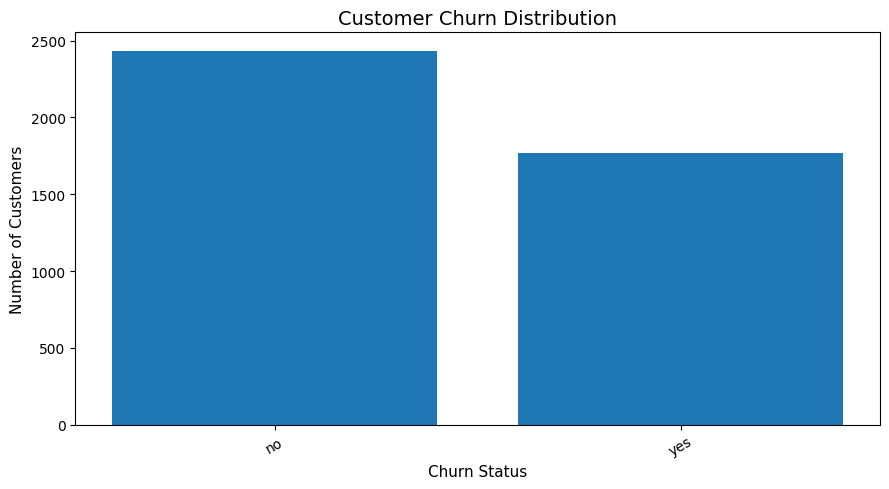

In [26]:
# Calculate churn distribution
churn_distribution = (
    customer_data['churned']
    .value_counts()
    .rename_axis('churn_status')
    .reset_index(name='customers')
                )

# Create bar chart
create_bar_chart(
   churn_distribution,
    'churn_status',
    'customers',
   'Customer Churn Distribution',
    'Churn Status',
    'Number of Customers'
)

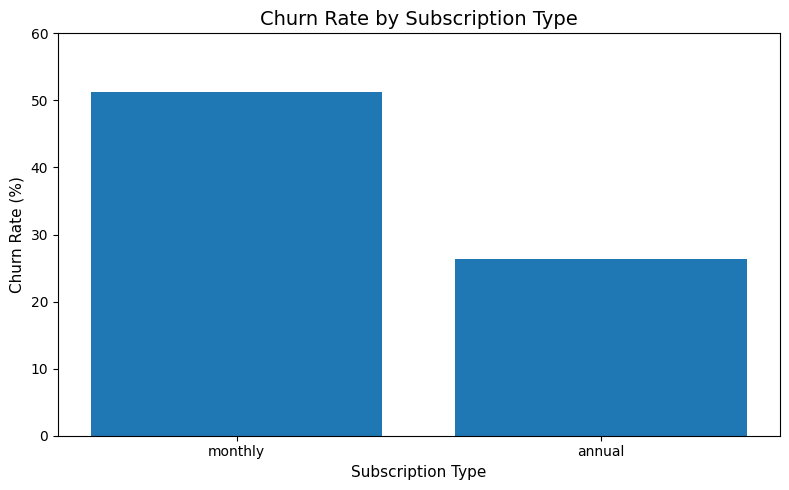

In [27]:
plt.figure(figsize=(8, 5))

plt.bar(
    plan_churn['plan_type'],
        plan_churn['churn_rate_pct']
        )

plt.title('Churn Rate by Subscription Type')
plt.xlabel('Subscription Type')
plt.ylabel('Churn Rate (%)')

plt.ylim(0, 60)
plt.tight_layout()
plt.show()

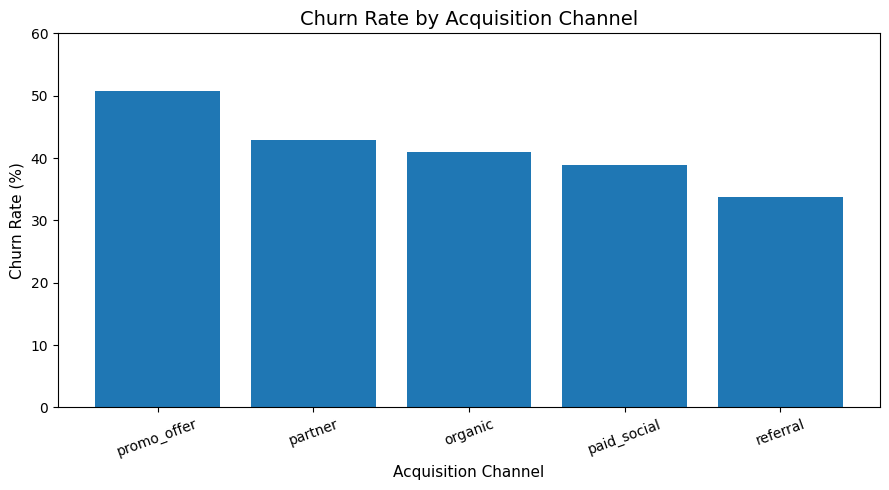

In [28]:
plt.figure(figsize=(9, 5))

plt.bar(
    channel_churn['acquisition_channel'],
        channel_churn['churn_rate_pct']
        )

plt.title('Churn Rate by Acquisition Channel')
plt.xlabel('Acquisition Channel')
plt.ylabel('Churn Rate (%)')

plt.ylim(0, 60)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

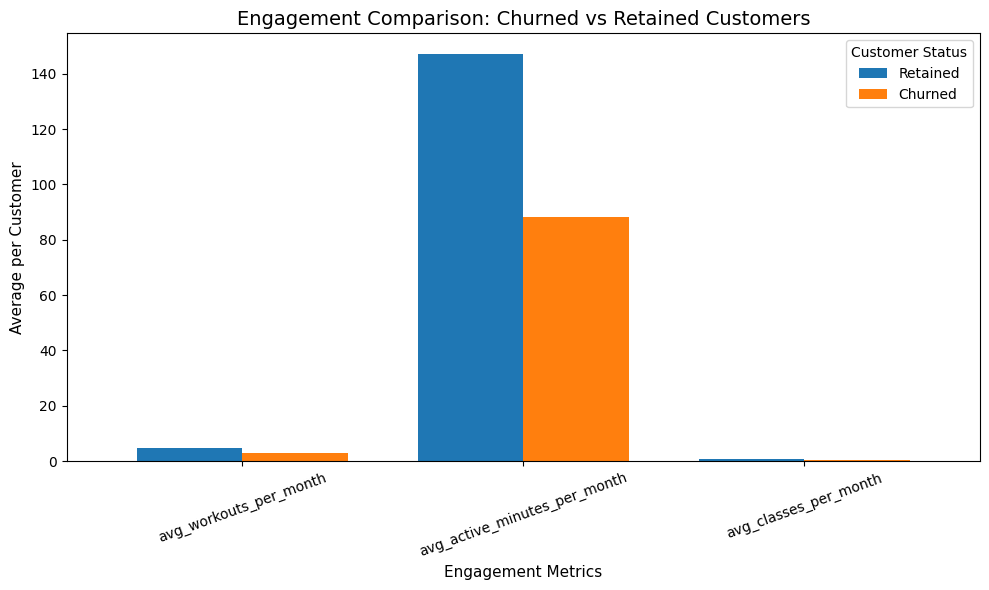

In [29]:
# Prepare engagement comparison for plotting
engagement_metrics = [
    'avg_workouts_per_month',
    'avg_active_minutes_per_month',
    'avg_classes_per_month'
            ]

engagement_plot = customer_data.groupby('churned')[
                engagement_metrics
                ].mean().T

# Create separate comparison bars
engagement_plot.plot(
                    kind='bar',
                    figsize=(10, 6),
                    width=0.75
                            )

plt.title('Engagement Comparison: Churned vs Retained Customers')
plt.xlabel('Engagement Metrics')
plt.ylabel('Average per Customer')
plt.xticks(rotation=20)
plt.legend(['Retained', 'Churned'], title='Customer Status')
plt.tight_layout()
plt.show()

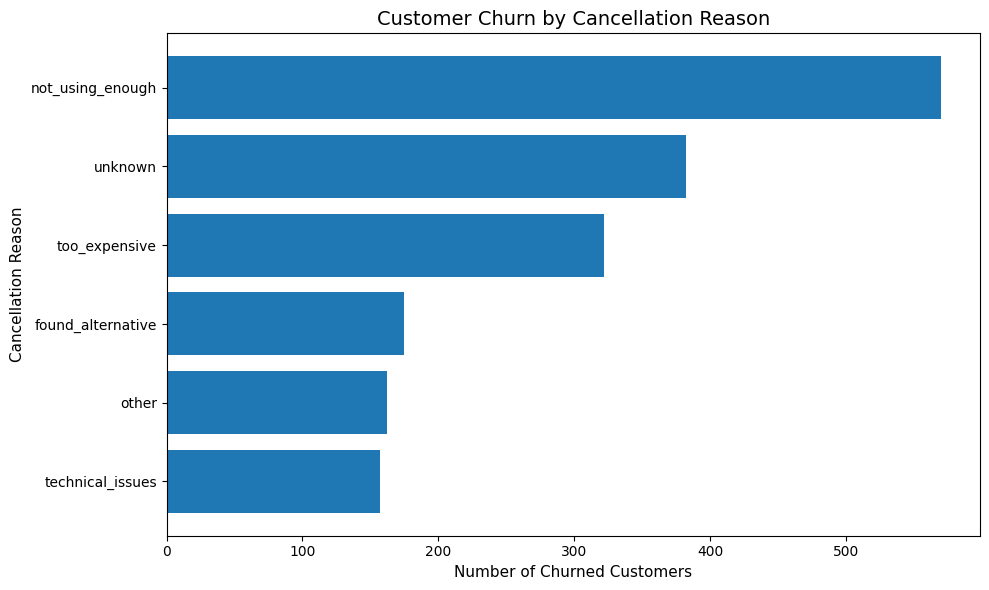

In [30]:
plt.figure(figsize=(10, 6))

plt.barh(
    cancellation_analysis['cancellation_reason'],
        cancellation_analysis['customers']
        )

plt.title('Customer Churn by Cancellation Reason')
plt.xlabel('Number of Churned Customers')
plt.ylabel('Cancellation Reason')

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

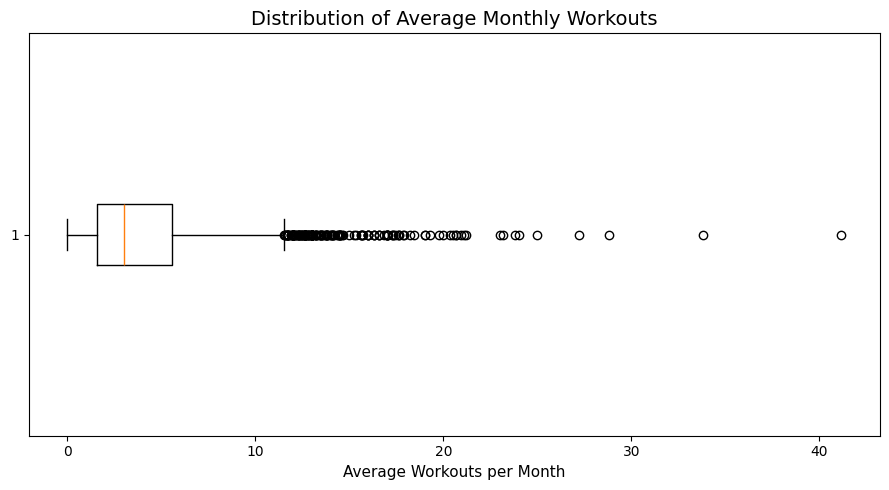

Workout frequency statistics:
count    4200.000000
mean        4.076242
std         3.475915
min         0.000000
25%         1.597059
50%         3.000000
75%         5.571429
max        41.166667
Name: avg_workouts_per_month, dtype: float64


In [31]:
plt.figure(figsize=(9, 5))

plt.boxplot(
    customer_data['avg_workouts_per_month'],
        vert=False
        )

plt.title('Distribution of Average Monthly Workouts')
plt.xlabel('Average Workouts per Month')

plt.tight_layout()
plt.show()

print("Workout frequency statistics:")
print(customer_data['avg_workouts_per_month'].describe())

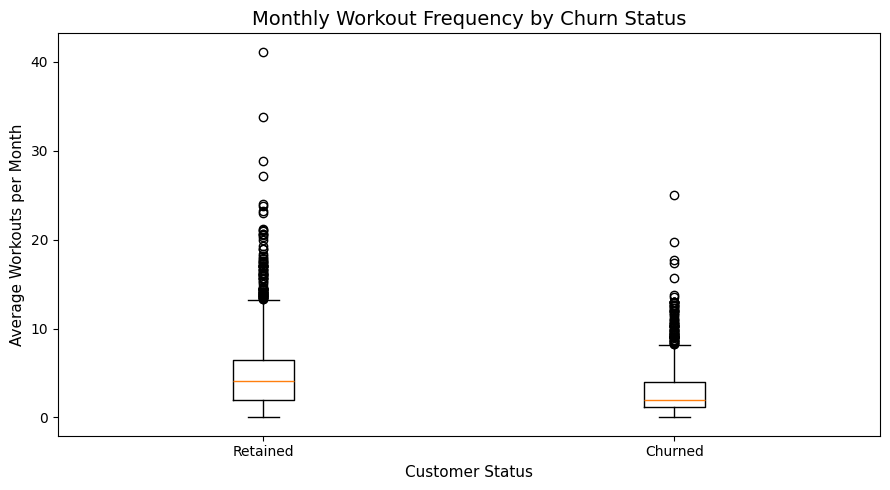

In [32]:
retained_workouts = customer_data.loc[
      customer_data['churned'] == 'no',
          'avg_workouts_per_month'
          ]

churned_workouts = customer_data.loc[
              customer_data['churned'] == 'yes',
                'avg_workouts_per_month'
                  ]

plt.figure(figsize=(9, 5))

plt.boxplot(
            [retained_workouts, churned_workouts],
            tick_labels=['Retained', 'Churned']
                          )

plt.title('Monthly Workout Frequency by Churn Status')
plt.xlabel('Customer Status')
plt.ylabel('Average Workouts per Month')

plt.tight_layout()
plt.show()


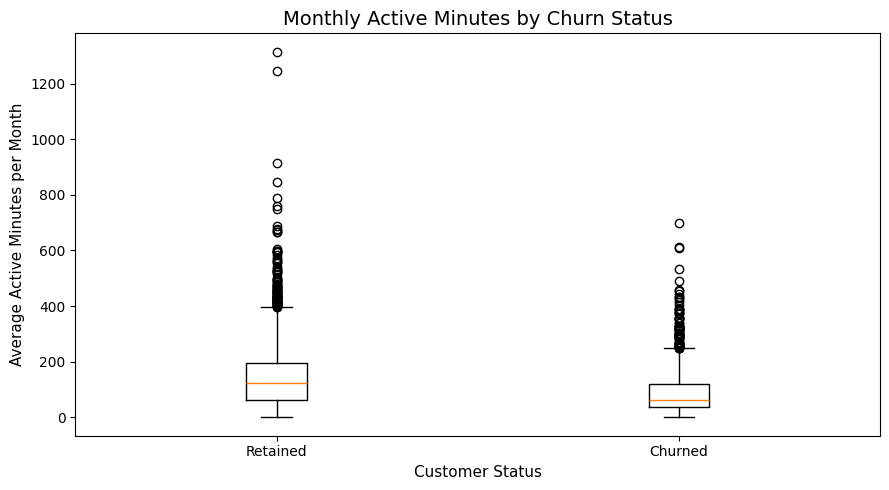

In [33]:
retained_minutes = customer_data.loc[
      customer_data['churned'] == 'no',
          'avg_active_minutes_per_month'
          ].dropna()

churned_minutes = customer_data.loc[
              customer_data['churned'] == 'yes',
              'avg_active_minutes_per_month'
                  ].dropna()

plt.figure(figsize=(9, 5))

plt.boxplot(
        [retained_minutes, churned_minutes],
         tick_labels=['Retained', 'Churned']
                          )

plt.title('Monthly Active Minutes by Churn Status')
plt.xlabel('Customer Status')
plt.ylabel('Average Active Minutes per Month')

plt.tight_layout()
plt.show()

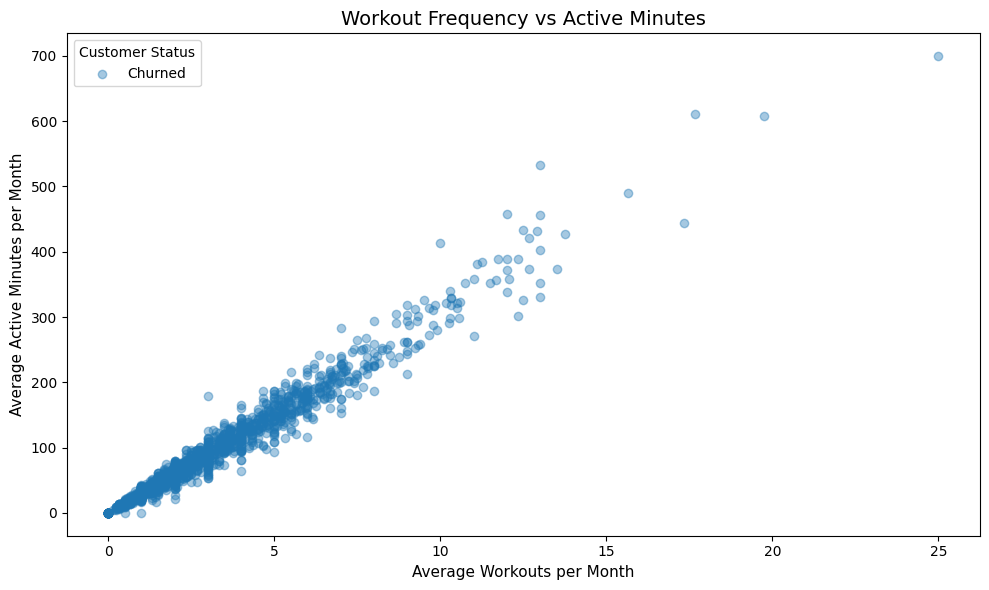

In [34]:
plt.figure(figsize=(10, 6))

for status in ['no', 'yes']:
    subset = customer_data[customer_data['churned'] == status]

plt.scatter(
          subset['avg_workouts_per_month'],
          subset['avg_active_minutes_per_month'],
          alpha=0.4,
          label='Retained' if status == 'no' else 'Churned'
                                            )

plt.title('Workout Frequency vs Active Minutes')
plt.xlabel('Average Workouts per Month')
plt.ylabel('Average Active Minutes per Month')
plt.legend(title='Customer Status')

plt.tight_layout()
plt.show()

In [35]:
# Verify churn categories in the customer dataset
print("Churn status values:")
print(customer_data['churned'].value_counts(dropna=False))

print("\nUnique values with exact representation:")
print([repr(value) for value in customer_data['churned'].unique()])

# Check number of records selected for each group
for status in ['no', 'yes']:
    subset = customer_data[customer_data['churned'] == status]
    print(f"{status}: {len(subset)} customers")

Churn status values:
churned
no     2432
yes    1768
Name: count, dtype: int64

Unique values with exact representation:
["'yes'", "'no'"]
no: 2432 customers
yes: 1768 customers


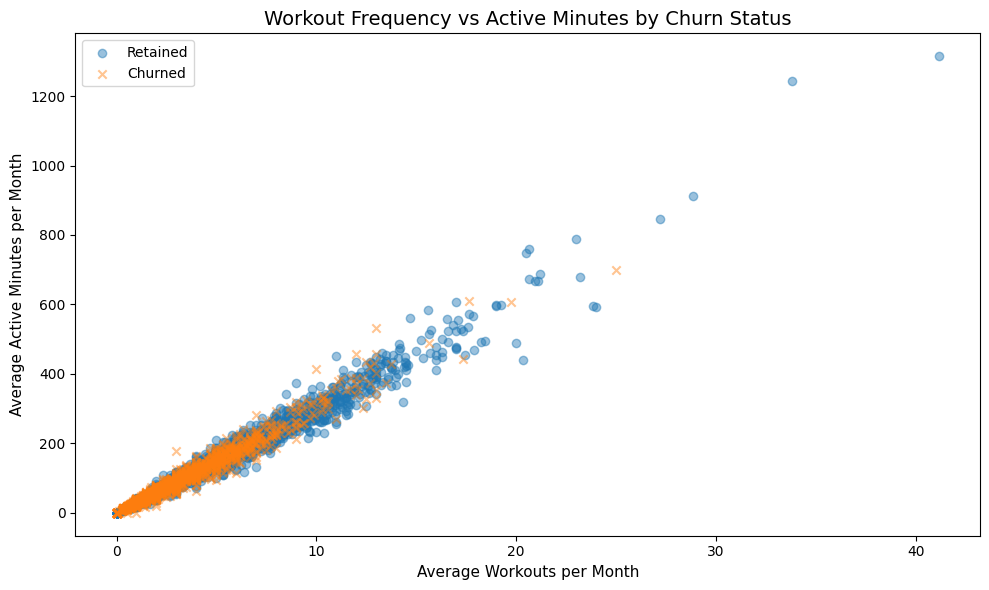

In [36]:
plt.figure(figsize=(10, 6))

retained = customer_data[customer_data['churned'] == 'no']
churned = customer_data[customer_data['churned'] == 'yes']

plt.scatter(
    retained['avg_workouts_per_month'],
    retained['avg_active_minutes_per_month'],
    alpha=0.45,
    label='Retained',
    marker='o'
)

plt.scatter(
  churned['avg_workouts_per_month'],
  churned['avg_active_minutes_per_month'],
   alpha=0.45,
   label='Churned',
   marker='x'
 )
plt.title('Workout Frequency vs Active Minutes by Churn Status')
plt.xlabel('Average Workouts per Month')
plt.ylabel('Average Active Minutes per Month')
plt.legend()

plt.tight_layout()
plt.show()

# Churn Prediction: Problem Formulation and Dataset Preparation

In [37]:
# Prepare subscription information
subscription_features = subscriptions[
    [
            'customer_id',
            'signup_date',
            'churn_date',
            'churned',
            'plan_type',
           'plan_tier',
           'monthly_price',
           'acquisition_channel',
           'primary_device',
           'age_group'
    ]
   ].copy()

# Identify signup and churn calendar months
subscription_features['signup_month'] = (
subscription_features['signup_date']
.dt.to_period('M')
.dt.to_timestamp()
)

subscription_features['churn_month'] = (
subscription_features['churn_date']
.dt.to_period('M')
.dt.to_timestamp()
)

 # Attach subscription details to monthly usage
early_usage = usage.merge(
    subscription_features,
    on='customer_id',
    how='inner'
  )

# Keep usage strictly after signup month
early_usage = early_usage[
    early_usage['month'] > early_usage['signup_month']
 ].copy()

# For churned customers, usage must be before churn month
early_usage = early_usage[
   (early_usage['churned'] == 'no') |
 (
     (early_usage['churned'] == 'yes') &
     (early_usage['month'] < early_usage['churn_month'])
)
].copy()

# Select the earliest eligible usage month per customer
early_usage = early_usage.sort_values('month')
first_month_data = (
    early_usage
    .groupby('customer_id')
    .first()
    .reset_index()
 )

# Check coverage
print("Original customers:", len(subscriptions))
print("Customers with a valid first-month observation:",len(first_month_data))

print("Customers excluded:", len(subscriptions) - len(first_month_data))


print("\nChurn distribution in modelling dataset:")
print(first_month_data['churned'].value_counts())

print("\nModelling dataset preview:")
display(first_month_data.head())

Original customers: 4200
Customers with a valid first-month observation: 3691
Customers excluded: 509

Churn distribution in modelling dataset:
churned
no     2293
yes    1398
Name: count, dtype: int64

Modelling dataset preview:


,customer_id,month,workouts_completed,minutes_active,classes_booked,support_tickets,signup_date,churn_date,churned,plan_type,plan_tier,monthly_price,acquisition_channel,primary_device,age_group,signup_month,churn_month
0,1,2024-10-01,4,116.0,0,0,2024-09-11,2025-06-29,yes,monthly,basic,12.99,promo_offer,android,45-54,2024-09-01,2025-06-01
1,2,2025-09-01,0,0.0,0,0,2025-08-14,NaT,no,annual,basic,9.74,promo_offer,web,45-54,2025-08-01,NaT
2,5,2025-07-01,1,41.0,0,0,2025-06-24,NaT,no,annual,plus,14.99,paid_social,android,55+,2025-06-01,NaT
3,6,2024-09-01,2,37.0,1,0,2024-08-11,2025-03-01,yes,monthly,plus,19.99,organic,web,55+,2024-08-01,2025-03-01
4,8,2025-11-01,3,85.0,0,0,2025-10-20,NaT,no,annual,plus,14.99,organic,web,45-54,2025-10-01,NaT


In [38]:
subscription_features = subscriptions[
      [
          'customer_id',
           'signup_date',
           'churn_date',
           'churned',
          'plan_type',
           'plan_tier',
            'monthly_price',
           'acquisition_channel',
           'primary_device',
           'age_group'
 ]
 ].copy()

subscription_features['signup_month'] = (
      subscription_features['signup_date']
      .dt.to_period('M')
      .dt.to_timestamp()
)

subscription_features['churn_month'] = (
      subscription_features['churn_date']
      .dt.to_period('M')
      .dt.to_timestamp()
)

subscription_features['observation_month'] = (
      subscription_features['signup_month']
      + pd.DateOffset(months=1)
 )

early_usage = usage.merge(
      subscription_features,
      on='customer_id',
      how='inner'
)

first_month_data = early_usage[
      early_usage['month'] == early_usage['observation_month']
      ].copy()

first_month_data = first_month_data[
      (first_month_data['churned'] == 'no') |
      (
          first_month_data['churn_month'] >
          first_month_data['observation_month']
       )
  ].copy()

print("Eligible customers:", len(first_month_data))
print("Duplicate customer IDs:", first_month_data['customer_id'].duplicated().sum())

print("\nChurn distribution:")
print(first_month_data['churned'].value_counts())

print("\nMissing first-month active minutes:",
      first_month_data['minutes_active'].isnull().sum())

print("\nFirst-month dataset preview:")
display(first_month_data.head())



Eligible customers: 3691
Duplicate customer IDs: 0

Churn distribution:
churned
no     2293
yes    1398
Name: count, dtype: int64

Missing first-month active minutes: 54

First-month dataset preview:


,customer_id,month,workouts_completed,minutes_active,classes_booked,support_tickets,signup_date,churn_date,churned,plan_type,plan_tier,monthly_price,acquisition_channel,primary_device,age_group,signup_month,churn_month,observation_month
1,1,2024-10-01,4,116.0,0,0,2024-09-11,2025-06-29,yes,monthly,basic,12.99,promo_offer,android,45-54,2024-09-01,2025-06-01,2024-10-01
11,2,2025-09-01,0,0.0,0,0,2025-08-14,NaT,no,annual,basic,9.74,promo_offer,web,45-54,2025-08-01,NaT,2025-09-01
18,5,2025-07-01,1,41.0,0,0,2025-06-24,NaT,no,annual,plus,14.99,paid_social,android,55+,2025-06-01,NaT,2025-07-01
25,6,2024-09-01,2,37.0,1,0,2024-08-11,2025-03-01,yes,monthly,plus,19.99,organic,web,55+,2024-08-01,2025-03-01,2024-09-01
35,8,2025-11-01,3,85.0,0,0,2025-10-20,NaT,no,annual,plus,14.99,organic,web,45-54,2025-10-01,NaT,2025-11-01


In [39]:
# Define the dataset observation cutoff
data_cutoff = pd.Timestamp('2026-01-01')

# Calculate the end of each customer's 3-month prediction window
first_month_data['followup_end'] = (
    first_month_data['observation_month']
        + pd.DateOffset(months=4)
        )

# Keep only customers with a complete 3-month follow-up
model_data = first_month_data[
            first_month_data['followup_end'] <= data_cutoff
            ].copy()

# Create the 3-month churn target
model_data['churn_within_3m'] = (
    model_data['churn_date'].notna()
    & (model_data['churn_date'] > model_data['observation_month'])
    & (model_data['churn_date'] < model_data['followup_end'])
).astype(int)

# Inspect the modelling dataset
print("Eligible customers:", len(model_data))

print("\n3-month churn target distribution:")
print(model_data['churn_within_3m'].value_counts())

print("\nTarget distribution (%):")
print(
    model_data['churn_within_3m']
     .value_counts(normalize=True)
     .mul(100)
     .round(2)
  )

print("\nObservation month range:")
print(model_data['observation_month'].min(),
        "to",
       model_data['observation_month'].max())

print("\nFinal dataset preview:")
display(model_data.head())

Eligible customers: 3161

3-month churn target distribution:
churn_within_3m
0    2596
1     565
Name: count, dtype: int64

Target distribution (%):
churn_within_3m
0    82.13
1    17.87
Name: proportion, dtype: float64

Observation month range:
2024-08-01 00:00:00 to 2025-09-01 00:00:00

Final dataset preview:


,customer_id,month,workouts_completed,minutes_active,classes_booked,support_tickets,signup_date,churn_date,churned,plan_type,plan_tier,monthly_price,acquisition_channel,primary_device,age_group,signup_month,churn_month,observation_month,followup_end,churn_within_3m
1,1,2024-10-01,4,116.0,0,0,2024-09-11,2025-06-29,yes,monthly,basic,12.99,promo_offer,android,45-54,2024-09-01,2025-06-01,2024-10-01,2025-02-01,0
11,2,2025-09-01,0,0.0,0,0,2025-08-14,NaT,no,annual,basic,9.74,promo_offer,web,45-54,2025-08-01,NaT,2025-09-01,2026-01-01,0
18,5,2025-07-01,1,41.0,0,0,2025-06-24,NaT,no,annual,plus,14.99,paid_social,android,55+,2025-06-01,NaT,2025-07-01,2025-11-01,0
25,6,2024-09-01,2,37.0,1,0,2024-08-11,2025-03-01,yes,monthly,plus,19.99,organic,web,55+,2024-08-01,2025-03-01,2024-09-01,2025-01-01,0
38,9,2024-09-01,2,68.0,0,0,2024-08-29,2025-07-27,yes,annual,basic,9.74,promo_offer,ios,25-34,2024-08-01,2025-07-01,2024-09-01,2025-01-01,0


# Train-Test Split and Data Preprocessing

In [40]:
from sklearn.model_selection import train_test_split


feature_columns = [
    'plan_type',
    'plan_tier',
    'monthly_price',
    'acquisition_channel',
    'primary_device',
    'age_group',
    'workouts_completed',
    'minutes_active',
    'classes_booked',
    'support_tickets'
]

X = model_data[feature_columns].copy()
y = model_data['churn_within_3m'].copy()


categorical_features = [
    'plan_type',
    'plan_tier',
     'acquisition_channel',
     'primary_device',
     'age_group'
]

numerical_features = [
      'monthly_price',
      'workouts_completed',
      'minutes_active',
      'classes_booked',
      'support_tickets'
 ]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
     stratify=y
 )

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

print("\nMissing values in training data:")
display(X_train.isnull().sum())

Training set: (2528, 10)
Testing set: (633, 10)

Training target distribution:
churn_within_3m
0    82.12
1    17.88
Name: proportion, dtype: float64

Testing target distribution:
churn_within_3m
0    82.15
1    17.85
Name: proportion, dtype: float64

Missing values in training data:


,0
plan_type,0
plan_tier,0
monthly_price,0
acquisition_channel,0
primary_device,0
age_group,0
workouts_completed,0
minutes_active,40
classes_booked,0
support_tickets,0


In [41]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical preprocessing
numeric_preprocessor = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
        ])

# Categorical preprocessing
categorical_preprocessor = Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='most_frequent')),
             ('encoder', OneHotEncoder(handle_unknown='ignore'))
                ])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_preprocessor, numerical_features),
    ('cat', categorical_preprocessor, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


# Initial Model Development and Experiments

In [42]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Logistic Regression pipeline
logistic_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
 ))
 ])

# Random Forest pipeline
random_forest_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        class_weight='balanced_subsample',
        random_state=42,
        n_jobs=-1
))
])

logistic_model.fit(X_train, y_train)
random_forest_model.fit(X_train, y_train)

print("Both models trained successfully!")

Both models trained successfully!


In [44]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Get predicted churn probabilities
y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

threshold_results = []

thresholds = np.arange(0.20, 0.71, 0.05)

for threshold in thresholds:
  y_pred_threshold = (y_prob_lr >= threshold).astype(int)
  threshold_results.append({
      "Threshold": round(threshold, 2),
      "Precision": precision_score(y_test, y_pred_threshold, zero_division=0),
       "Recall": recall_score(y_test, y_pred_threshold, zero_division=0),
        "F1-score": f1_score(y_test, y_pred_threshold, zero_division=0)
        })
  threshold_df = pd.DataFrame(threshold_results)
  threshold_df.round(3)
  print(threshold_df)

   Threshold  Precision    Recall  F1-score
0        0.2   0.280323  0.920354  0.429752
   Threshold  Precision    Recall  F1-score
0       0.20   0.280323  0.920354  0.429752
1       0.25   0.289326  0.911504  0.439232
   Threshold  Precision    Recall  F1-score
0       0.20   0.280323  0.920354  0.429752
1       0.25   0.289326  0.911504  0.439232
2       0.30   0.302395  0.893805  0.451902
   Threshold  Precision    Recall  F1-score
0       0.20   0.280323  0.920354  0.429752
1       0.25   0.289326  0.911504  0.439232
2       0.30   0.302395  0.893805  0.451902
3       0.35   0.312500  0.884956  0.461894
   Threshold  Precision    Recall  F1-score
0       0.20   0.280323  0.920354  0.429752
1       0.25   0.289326  0.911504  0.439232
2       0.30   0.302395  0.893805  0.451902
3       0.35   0.312500  0.884956  0.461894
4       0.40   0.326599  0.858407  0.473171
   Threshold  Precision    Recall  F1-score
0       0.20   0.280323  0.920354  0.429752
1       0.25   0.289326  0.91150

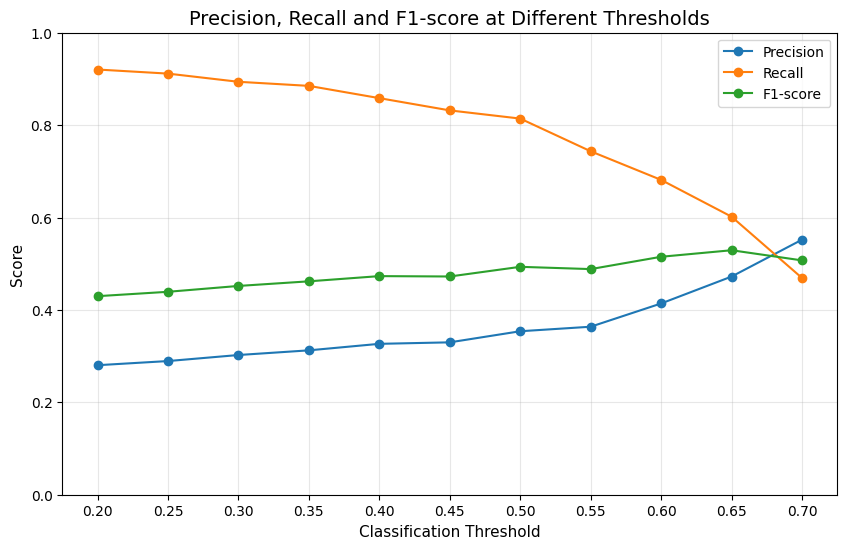

In [45]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
 )

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1-score"],
    marker="o",
    label="F1-score"
 )

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1-score at Different Thresholds")
plt.xticks(threshold_df["Threshold"])
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [46]:
from sklearn.metrics import classification_report, confusion_matrix

selected_threshold = 0.50

y_pred_final = (
    logistic_model.predict_proba(X_test)[:, 1] >= selected_threshold
    ).astype(int)
print("Selected Threshold:", selected_threshold)

print("\nFinal Classification Report:")
print(classification_report(y_test, y_pred_final))

print("Final Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_final))

Selected Threshold: 0.5

Final Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.68      0.79       520
           1       0.35      0.81      0.49       113

    accuracy                           0.70       633
   macro avg       0.65      0.75      0.64       633
weighted avg       0.84      0.70      0.74       633

Final Confusion Matrix:
[[352 168]
 [ 21  92]]


In [47]:
# Standardise plan-tier categories
model_data["plan_tier"] = (
    model_data["plan_tier"]
    .astype("string")
    .str.strip()
    .str.lower()
 )

# Inspect the cleaned categories
print("Plan-tier distribution:")
print(model_data["plan_tier"].value_counts(dropna=False))

Plan-tier distribution:
plan_tier
basic      1507
plus       1115
premium     539
Name: count, dtype: Int64


In [48]:
# Rebuild features and target
X = model_data[feature_columns].copy()
y = model_data["churn_within_3m"].copy()

# Repeat stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
 )

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining churn distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting churn distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training data: (2528, 10)
Testing data: (633, 10)

Training churn distribution:
churn_within_3m
0    0.821
1    0.179
Name: proportion, dtype: float64

Testing churn distribution:
churn_within_3m
0    0.821
1    0.179
Name: proportion, dtype: float64


In [49]:
# Rebuild Logistic Regression
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
 ))
])

# Rebuild Random Forest
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
))
])

# Train both models
logistic_model.fit(X_train, y_train)
random_forest_model.fit(X_train, y_train)
print("Both models retrained successfully!")

Both models retrained successfully!


In [50]:
from sklearn.metrics import (
      accuracy_score,
      roc_auc_score,
      precision_score,
      recall_score,
      f1_score
 )

models = {
    "Logistic Regression": logistic_model,
     "Random Forest": random_forest_model
}

evaluation_results = []
for name, model in models.items():
  y_pred = model.predict(X_test)
  y_prob = model.predict_proba(X_test)[:, 1]
  evaluation_results.append({
       "Model": name,
       "Accuracy": accuracy_score(y_test, y_pred),
       "ROC-AUC": roc_auc_score(y_test, y_prob),
      "Precision": precision_score(y_test, y_pred),
      "Recall": recall_score(y_test, y_pred),
      "F1-score": f1_score(y_test, y_pred)
})

evaluation_df = pd.DataFrame(evaluation_results)

evaluation_df.round(3)


,Model,Accuracy,ROC-AUC,Precision,Recall,F1-score
0,Logistic Regression,0.701,0.826,0.354,0.814,0.493
1,Random Forest,0.825,0.800,0.521,0.221,0.311


In [51]:
# Extract fitted preprocessing and classifier
fitted_preprocessor = logistic_model.named_steps["preprocessor"]
fitted_classifier = logistic_model.named_steps["classifier"]

# Get feature names and coefficients
feature_names = fitted_preprocessor.get_feature_names_out()
coefficients = fitted_classifier.coef_[0]

# Create coefficient DataFrame
coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
   })

# Calculate odds ratios for interpretation
coefficient_df["Odds_Ratio"] = np.exp(
      coefficient_df["Coefficient"]
  )

coefficient_df["Absolute_Coefficient"] = (
         coefficient_df["Coefficient"].abs()
   )

# Sort by coefficient magnitude
coefficient_df = coefficient_df.sort_values(
    "Absolute_Coefficient",
    ascending=False
)
coefficient_df.head(15).round(3)

,Feature,Coefficient,Odds_Ratio,Absolute_Coefficient
5,cat__plan_type_annual,-1.532,0.216,1.532
6,cat__plan_type_monthly,1.172,3.229,1.172
1,num__workouts_completed,-1.013,0.363,1.013
9,cat__plan_tier_premium,-0.800,0.449,0.800
13,cat__acquisition_channel_promo_offer,0.771,2.161,0.771
7,cat__plan_tier_basic,0.612,1.844,0.612
0,num__monthly_price,0.588,1.801,0.588
14,cat__acquisition_channel_referral,-0.415,0.660,0.415
22,cat__age_group_55+,-0.402,0.669,0.402
10,cat__acquisition_channel_organic,-0.323,0.724,0.323


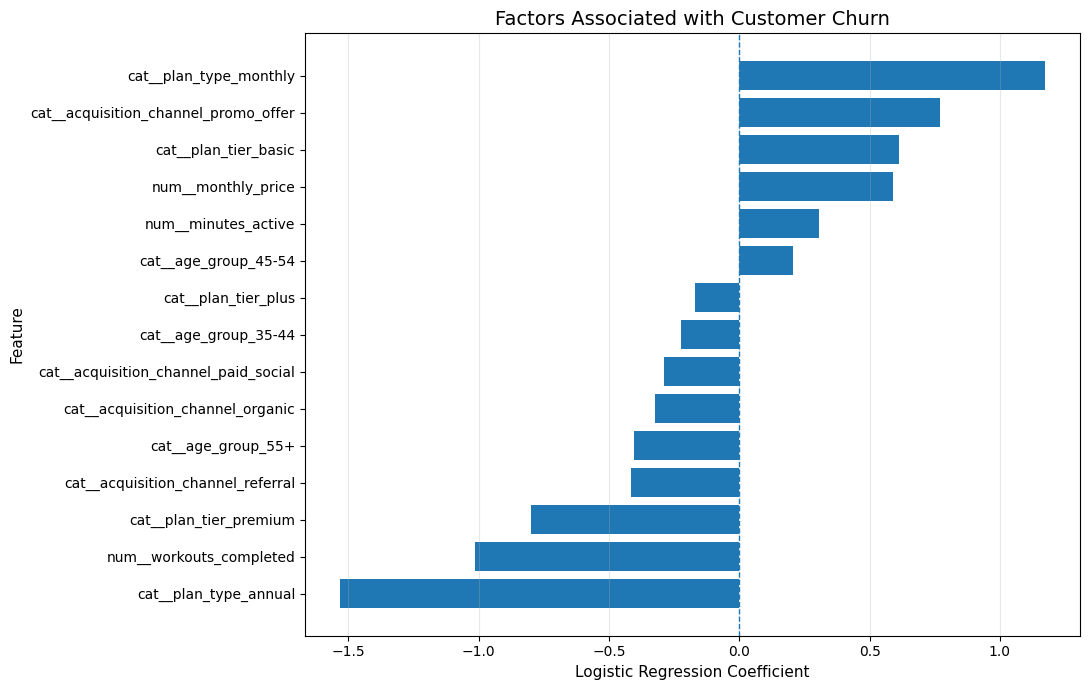

In [52]:
# Select the 15 strongest features
plot_data = coefficient_df.head(15).sort_values(
    "Coefficient"
    )

plt.figure(figsize=(11, 7))

plt.barh(
        plot_data["Feature"],
        plot_data["Coefficient"]
            )

plt.axvline(0, linestyle="--", linewidth=1)

plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.title("Factors Associated with Customer Churn")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [53]:
business_insights = pd.DataFrame({
      "Area": [
          "Subscription Type",
          "Customer Engagement",
          "Acquisition Channel",
          "Pricing",
          "Plan Tier",
          "Cancellation Reasons",
          "Customer Retention"
     ],
"Key Finding": [
          "Monthly subscribers have a 51.18% churn rate compared with 26.38% for annual subscribers.",
           "Retained customers complete an average of 4.90 workouts per month compared with 2.94 for churned customers.",
           "Customers acquired through promotional offers have a 50.79% churn rate, the highest among acquisition channels.",
           "Higher monthly prices are positively associated with predicted churn in the Logistic Regression model.",
           "Basic subscribers have a 42.05% churn rate, compared with 43.43% for Premium and 41.51% for Plus.",
           "Not using the service enough is the most frequently reported cancellation reason, accounting for 32.24% of churned customers.",
           "Logistic Regression identifies 81.4% of customers who churn within the three-month prediction window at the default threshold."
   ],

"Business Recommendation": [
          "Explore annual subscription incentives and conversion strategies.",
          "Develop personalised engagement campaigns to encourage consistent workouts.",
          "Evaluate the long-term retention and customer lifetime value of promotional campaigns.",
          "Investigate price sensitivity and test targeted pricing or value-based offers.",
          "Investigate differences in customer expectations and engagement across subscription tiers.",
          "Introduce onboarding, personalised recommendations and re-engagement campaigns.",
         "Use churn scores to prioritise customers for retention interventions, while monitoring false positives."
 ]
})

business_insights

,Area,Key Finding,Business Recommendation
0,Subscription Type,Monthly subscribers have a 51.18% churn rate c...,Explore annual subscription incentives and con...
1,Customer Engagement,Retained customers complete an average of 4.90...,Develop personalised engagement campaigns to e...
2,Acquisition Channel,Customers acquired through promotional offers ...,Evaluate the long-term retention and customer ...
3,Pricing,Higher monthly prices are positively associate...,Investigate price sensitivity and test targete...
4,Plan Tier,"Basic subscribers have a 42.05% churn rate, co...",Investigate differences in customer expectatio...
5,Cancellation Reasons,Not using the service enough is the most frequ...,"Introduce onboarding, personalised recommendat..."
6,Customer Retention,Logistic Regression identifies 81.4% of custom...,Use churn scores to prioritise customers for r...


In [54]:
# Export customer-level descriptive analysis dataset
customer_data.to_csv(
    base_path + "customer_churn_analysis.csv",
     index=False
        )

# Export modelling dataset
model_data.to_csv(
    base_path + "customer_churn_prediction.csv",
    index=False
   )

print("Datasets exported successfully!")
print("1. customer_churn_analysis.csv")
print("2. customer_churn_prediction.csv")

Datasets exported successfully!
1. customer_churn_analysis.csv
2. customer_churn_prediction.csv


# Final Model Training and Validation

In [55]:
from sklearn.model_selection import train_test_split

# Split the existing training data into training and validation sets
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    random_state=42,
    stratify=y_train
)

print("Model training set:", X_fit.shape)
print("Validation set:", X_val.shape)
print("Final test set:", X_test.shape)

print("\nChurn distribution:")
print("Training:", round(y_fit.mean(), 3))
print("Validation:", round(y_val.mean(), 3))
print("Testing:", round(y_test.mean(), 3))

Model training set: (1896, 10)
Validation set: (632, 10)
Final test set: (633, 10)

Churn distribution:
Training: 0.179
Validation: 0.179
Testing: 0.179


In [56]:
# Create a fresh Logistic Regression pipeline
final_logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
))
])

# Train using only the training subset
final_logistic_model.fit(X_fit, y_fit)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [57]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Predict churn probabilities on the validation set
val_probabilities = final_logistic_model.predict_proba(X_val)[:, 1]

# Evaluate different classification thresholds
thresholds = [0.30, 0.40, 0.50, 0.60, 0.65, 0.70]

threshold_results = []

for threshold in thresholds:
  val_predictions = (val_probabilities >= threshold).astype(int)
  threshold_results.append({
      "Threshold": threshold,
      "Precision": precision_score(y_val, val_predictions),
      "Recall": recall_score(y_val, val_predictions),
      "F1 Score": f1_score(y_val, val_predictions)
   })

threshold_df = pd.DataFrame(threshold_results)

threshold_df.round(3)

,Threshold,Precision,Recall,F1 Score
0,0.30,0.313,0.947,0.470
1,0.40,0.344,0.894,0.496
2,0.50,0.362,0.832,0.504
3,0.60,0.416,0.637,0.503
4,0.65,0.392,0.513,0.444
5,0.70,0.439,0.442,0.441


In [58]:
from sklearn.metrics import (
      accuracy_score,
      precision_score,
      recall_score,
      f1_score,
      roc_auc_score,
      confusion_matrix,
      classification_report
 )

# Lock the threshold selected using validation data
FINAL_THRESHOLD = 0.50

# Predict probabilities on the untouched test set
test_probabilities = final_logistic_model.predict_proba(X_test)[:, 1]

# Convert probabilities into binary predictions
test_predictions = (
      test_probabilities >= FINAL_THRESHOLD
).astype(int)

# Evaluate final model
print("Final Test Set Performance")
print("---------------------------")
print("Threshold:", FINAL_THRESHOLD)
print("Accuracy:", round(accuracy_score(y_test, test_predictions), 3))
print("Precision:", round(precision_score(y_test, test_predictions), 3))
print("Recall:", round(recall_score(y_test, test_predictions), 3))
print("F1 Score:", round(f1_score(y_test, test_predictions), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, test_probabilities), 3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_predictions))

print("\nClassification Report:")
print(classification_report(y_test, test_predictions))

Final Test Set Performance
---------------------------
Threshold: 0.5
Accuracy: 0.703
Precision: 0.352
Recall: 0.788
F1 Score: 0.486
ROC-AUC: 0.819

Confusion Matrix:
[[356 164]
 [ 24  89]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.68      0.79       520
           1       0.35      0.79      0.49       113

    accuracy                           0.70       633
   macro avg       0.64      0.74      0.64       633
weighted avg       0.83      0.70      0.74       633



In [59]:
performance_comparison = pd.DataFrame({
      "Metric": ["Precision", "Recall", "F1 Score"],
      "Validation": [0.362, 0.832, 0.504],
      "Test": [
                precision_score(y_test, test_predictions),
                recall_score(y_test, test_predictions),
                f1_score(y_test, test_predictions)
    ]
   })
performance_comparison.round(3)


,Metric,Validation,Test
0,Precision,0.362,0.352
1,Recall,0.832,0.788
2,F1 Score,0.504,0.486


In [60]:
final_metrics = pd.DataFrame({
      "Metric": [
          "Accuracy",
          "Precision",
           "Recall",
          "F1 Score",
         "ROC-AUC"
 ],
 "Value": [
     accuracy_score(y_test, test_predictions),
     precision_score(y_test, test_predictions),
    recall_score(y_test, test_predictions),
     f1_score(y_test, test_predictions),
     roc_auc_score(y_test, test_probabilities)
]
})

final_metrics["Value"] = final_metrics["Value"].round(3)

final_metrics.to_csv(
    base_path + "final_model_metrics.csv",
   index=False
)
final_metrics

,Metric,Value
0,Accuracy,0.703
1,Precision,0.352
2,Recall,0.788
3,F1 Score,0.486
4,ROC-AUC,0.819


In [61]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_candidate = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=10,
        min_samples_split=10,
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
  ))
  ])
rf_candidate.fit(X_fit, y_fit)
print("Random Forest trained successfully!")

Random Forest trained successfully!


In [62]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Predict churn probabilities on validation data
rf_val_probabilities = rf_candidate.predict_proba(X_val)[:, 1]

# Evaluate different thresholds
rf_threshold_results = []

for threshold in [0.30, 0.40, 0.50, 0.60, 0.65, 0.70]:
  rf_val_predictions = (
      rf_val_probabilities >= threshold
).astype(int)

rf_threshold_results.append({
    "Threshold": threshold,
    "Precision": precision_score(y_val, rf_val_predictions),
    "Recall": recall_score(y_val, rf_val_predictions),
     "F1 Score": f1_score(y_val, rf_val_predictions)
})
rf_threshold_df = pd.DataFrame(rf_threshold_results)
rf_threshold_df.round(3)

,Threshold,Precision,Recall,F1 Score
0,0.7,0.55,0.292,0.382


In [63]:
print("Random Forest validation results:")
display(rf_threshold_df.round(3))

print("\nNumber of unique predicted probabilities:")
print(rf_val_probabilities.min(), rf_val_probabilities.max())

print("\nUnique probability count:")
print(len(np.unique(rf_val_probabilities)))

Random Forest validation results:


,Threshold,Precision,Recall,F1 Score
0,0.7,0.55,0.292,0.382



Number of unique predicted probabilities:
0.005373082543186172 0.9176111731351941

Unique probability count:
624


In [64]:
rf_thresholds_check = [0.30, 0.40, 0.50, 0.60, 0.65, 0.70]

rf_results_check = []

for t in rf_thresholds_check:
  pred = (rf_val_probabilities >= t).astype(int)
  rf_results_check.append({
      "Threshold": t,
      "Predicted_Churners": int(pred.sum()),
      "Actual_Churners": int(y_val.sum()),
      "Precision": precision_score(y_val, pred, zero_division=0),
      "Recall": recall_score(y_val, pred, zero_division=0),
      "F1": f1_score(y_val, pred, zero_division=0)
})

print("Thresholds evaluated:", len(rf_results_check))
print("Results generated:", len(rf_results_check))

pd.DataFrame(rf_results_check).round(3)

Thresholds evaluated: 6
Results generated: 6


,Threshold,Predicted_Churners,Actual_Churners,Precision,Recall,F1
0,0.30,308,113,0.328,0.894,0.480
1,0.40,264,113,0.367,0.858,0.515
2,0.50,199,113,0.392,0.690,0.500
3,0.60,123,113,0.463,0.504,0.483
4,0.65,83,113,0.482,0.354,0.408
5,0.70,60,113,0.550,0.292,0.382


In [65]:
from sklearn.metrics import (
      accuracy_score,
      precision_score,
      recall_score,
      f1_score,
      roc_auc_score,
      confusion_matrix
 )

RF_FINAL_THRESHOLD = 0.40

# Generate test probabilities
rf_test_probabilities = rf_candidate.predict_proba(X_test)[:, 1]

# Apply validation-selected threshold
rf_test_predictions = (
    rf_test_probabilities >= RF_FINAL_THRESHOLD
    ).astype(int)

 # Calculate final test metrics
rf_test_metrics = {
    "Accuracy": accuracy_score(y_test, rf_test_predictions),
    "Precision": precision_score(y_test, rf_test_predictions),
    "Recall": recall_score(y_test, rf_test_predictions),
    "F1 Score": f1_score(y_test, rf_test_predictions),
    "ROC-AUC": roc_auc_score(y_test, rf_test_probabilities)
}

print("Random Forest - Final Test Performance")
print("---------------------------------------")

for metric, value in rf_test_metrics.items():
  print(f"{metric}: {value:.3f}")
  print("\nConfusion Matrix:")
  print(confusion_matrix(y_test, rf_test_predictions))

Random Forest - Final Test Performance
---------------------------------------
Accuracy: 0.701

Confusion Matrix:
[[352 168]
 [ 21  92]]
Precision: 0.354

Confusion Matrix:
[[352 168]
 [ 21  92]]
Recall: 0.814

Confusion Matrix:
[[352 168]
 [ 21  92]]
F1 Score: 0.493

Confusion Matrix:
[[352 168]
 [ 21  92]]
ROC-AUC: 0.827

Confusion Matrix:
[[352 168]
 [ 21  92]]


In [66]:
# Logistic Regression validation predictions at threshold 0.40
lr_val_predictions_040 = (
    val_probabilities >= 0.40
    ).astype(int)

lr_040_metrics = {
    "Threshold": 0.40,
    "Precision": precision_score(y_val, lr_val_predictions_040),
    "Recall": recall_score(y_val, lr_val_predictions_040),
    "F1 Score": f1_score(y_val, lr_val_predictions_040)
    }
pd.DataFrame([lr_040_metrics]).round(3)

,Threshold,Precision,Recall,F1 Score
0,0.4,0.344,0.894,0.496


In [67]:
LR_THRESHOLD_040 = 0.40

lr_test_predictions_040 = (
    test_probabilities >= LR_THRESHOLD_040
    ).astype(int)

print("Logistic Regression - Test Performance (Threshold 0.40)")
print("--------------------------------------------------------")
print("Precision:", round(
        precision_score(y_test, lr_test_predictions_040), 3
        ))
print("Recall:", round(
            recall_score(y_test, lr_test_predictions_040), 3
            ))
print("F1 Score:", round(
                f1_score(y_test, lr_test_predictions_040), 3
                ))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, lr_test_predictions_040))

Logistic Regression - Test Performance (Threshold 0.40)
--------------------------------------------------------
Precision: 0.325
Recall: 0.85
F1 Score: 0.471

Confusion Matrix:
[[321 199]
 [ 17  96]]


In [68]:
model_comparison = pd.DataFrame({
      "Model": [
          "Logistic Regression",
           "Logistic Regression",
           "Random Forest"
           ],
      "Threshold": [0.50, 0.40, 0.40],
      "Accuracy": [
           accuracy_score(y_test, test_predictions),
           accuracy_score(y_test, lr_test_predictions_040),
           accuracy_score(y_test, rf_test_predictions)
            ],
      "Precision": [
          precision_score(y_test, test_predictions),
          precision_score(y_test, lr_test_predictions_040),
          precision_score(y_test, rf_test_predictions)
          ],
      "Recall": [
          recall_score(y_test, test_predictions),
          recall_score(y_test, lr_test_predictions_040),
          recall_score(y_test, rf_test_predictions)
          ],
      "F1 Score": [
          f1_score(y_test, test_predictions),
          f1_score(y_test, lr_test_predictions_040),
          f1_score(y_test, rf_test_predictions)
          ],
      "ROC-AUC": [
          roc_auc_score(y_test, test_probabilities),
          roc_auc_score(y_test, test_probabilities),
          roc_auc_score(y_test, rf_test_probabilities)
          ]
      })

model_comparison = model_comparison.round(3)

model_comparison.to_csv(
    base_path + "model_comparison.csv",
    index=False
)

model_comparison

,Model,Threshold,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.5,0.703,0.352,0.788,0.486,0.819
1,Logistic Regression,0.4,0.659,0.325,0.850,0.471,0.819
2,Random Forest,0.4,0.701,0.354,0.814,0.493,0.827


# Model Comparison and Selection

In [69]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline

gb_candidate = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=2,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42
        ))
    ])

gb_candidate.fit(X_fit, y_fit)

print("Gradient Boosting trained successfully!")

Gradient Boosting trained successfully!


In [70]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Predict churn probabilities on validation data
gb_val_probabilities = gb_candidate.predict_proba(X_val)[:, 1]

# Evaluate classification thresholds
gb_thresholds = [0.30, 0.40, 0.50, 0.60, 0.65, 0.70]

gb_results = []

for threshold in gb_thresholds:
    predictions = (gb_val_probabilities >= threshold).astype(int)
    gb_results.append({
              "Threshold": threshold,
              "Predicted_Churners": int(predictions.sum()),
              "Precision": precision_score(
                  y_val, predictions, zero_division=0
                  ),
              "Recall": recall_score(
                  y_val, predictions, zero_division=0
                  ),
              "F1 Score": f1_score(
                  y_val, predictions, zero_division=0
                  )
              })
gb_threshold_df = pd.DataFrame(gb_results)

display(gb_threshold_df.round(3))

,Threshold,Predicted_Churners,Precision,Recall,F1 Score
0,0.30,107,0.449,0.425,0.436
1,0.40,71,0.521,0.327,0.402
2,0.50,44,0.591,0.230,0.331
3,0.60,23,0.696,0.142,0.235
4,0.65,12,0.833,0.088,0.160
5,0.70,9,1.000,0.080,0.148


In [71]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# HistGradientBoosting requires numerical input.
# Use ordinal encoding for categorical columns.
hist_preprocessor = ColumnTransformer(
    transformers=[
            ("num", SimpleImputer(strategy="median"), numerical_features),
            ("cat", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1
                ))
            ]), categorical_features)
            ]
    )

hist_candidate = Pipeline(steps=[
    ("preprocessor", hist_preprocessor),
     ("classifier", HistGradientBoostingClassifier(
         max_iter=150,
        learning_rate=0.05,
        max_leaf_nodes=15,
       l2_regularization=1.0,
       random_state=42
         ))
       ])

hist_candidate.fit(X_fit, y_fit)
print("HistGradientBoosting trained successfully!")

HistGradientBoosting trained successfully!


In [72]:
from sklearn.metrics import precision_score, recall_score, f1_score

hist_val_probabilities = hist_candidate.predict_proba(X_val)[:, 1]

thresholds = [0.30, 0.40, 0.50, 0.60, 0.65, 0.70]

hist_results = []

for threshold in thresholds:
    predictions = (hist_val_probabilities >= threshold).astype(int)
    hist_results.append({
        "Threshold": threshold,
         "Precision": precision_score(y_val, predictions, zero_division=0),
          "Recall": recall_score(y_val, predictions, zero_division=0),
         "F1 Score": f1_score(y_val, predictions, zero_division=0),
          "Predicted Churners": predictions.sum()
          })
hist_results_df = pd.DataFrame(hist_results)
hist_results_df.round(3)

,Threshold,Precision,Recall,F1 Score,Predicted Churners
0,0.30,0.468,0.522,0.494,126
1,0.40,0.534,0.345,0.419,73
2,0.50,0.562,0.239,0.335,48
3,0.60,0.714,0.177,0.284,28
4,0.65,0.778,0.124,0.214,18
5,0.70,0.875,0.062,0.116,8


# Model Interpretation and Evaluation

In [73]:
from sklearn.inspection import permutation_importance

rf_permutation = permutation_importance(
    rf_candidate,
    X_val,
    y_val,
    scoring="f1",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
    )

feature_importance = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance": rf_permutation.importances_mean,
    "Std": rf_permutation.importances_std
    })

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
    ).reset_index(drop=True)

feature_importance.round(4)

,Feature,Importance,Std
0,plan_type,0.1885,0.0260
1,workouts_completed,0.0298,0.0125
2,minutes_active,0.0248,0.0150
3,classes_booked,0.0090,0.0115
4,monthly_price,0.0079,0.0173
5,primary_device,0.0030,0.0060
6,acquisition_channel,-0.0001,0.0106
7,support_tickets,-0.0022,0.0019
8,age_group,-0.0081,0.0111
9,plan_tier,-0.0115,0.0070


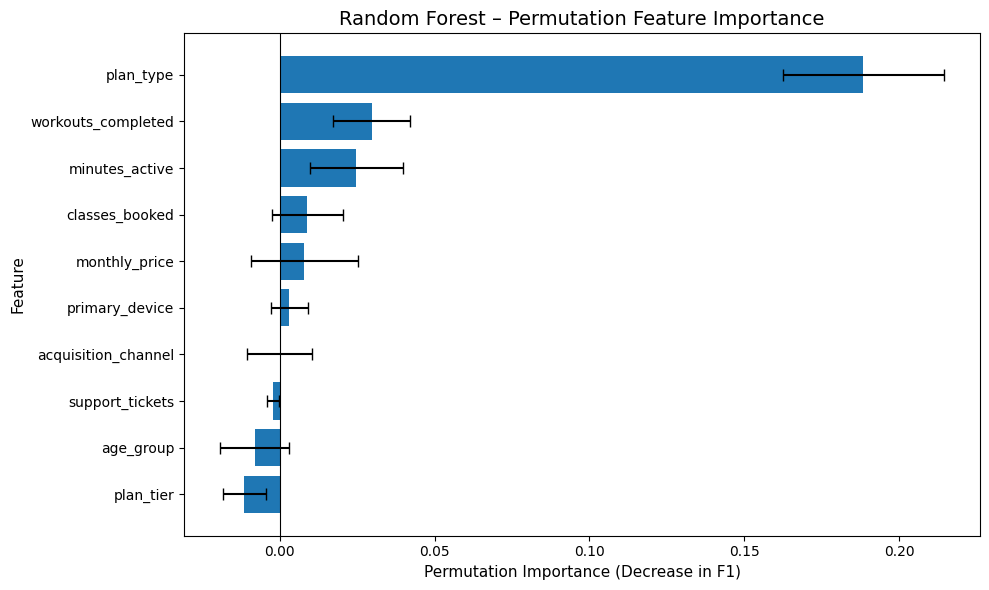

In [74]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"],
    xerr=feature_importance["Std"],
    capsize=4
    )

plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Permutation Importance (Decrease in F1)")
plt.ylabel("Feature")
plt.title("Random Forest – Permutation Feature Importance")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

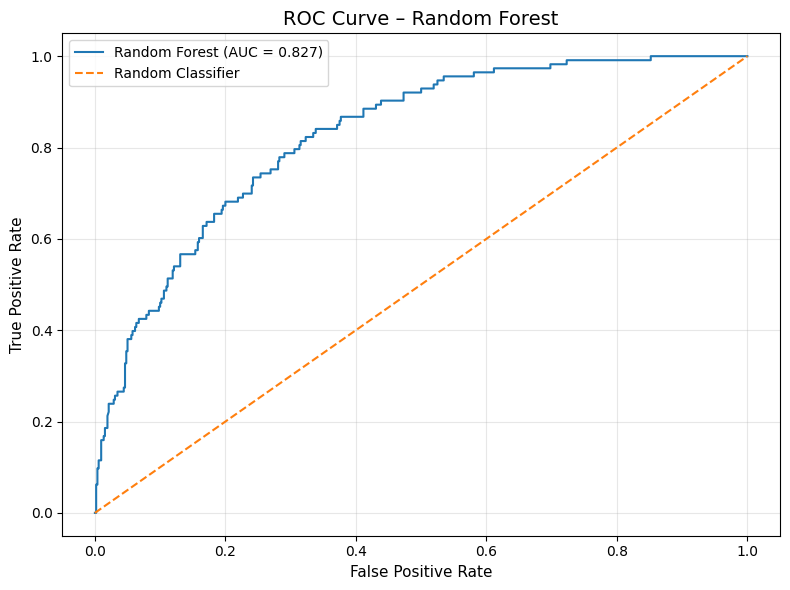

In [75]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Get churn probabilities for the test set
rf_test_probabilities = rf_candidate.predict_proba(X_test)[:, 1]

# Calculate ROC curve values
fpr, tpr, thresholds_roc = roc_curve(
    y_test,
    rf_test_probabilities
    )

# Calculate ROC-AUC
rf_roc_auc = roc_auc_score(
            y_test,
            rf_test_probabilities
                )

 # Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {rf_roc_auc:.3f})"
)

plt.plot(
    [0, 1],
     [0, 1],
     linestyle="--",
    label="Random Classifier"
 )

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve – Random Forest")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

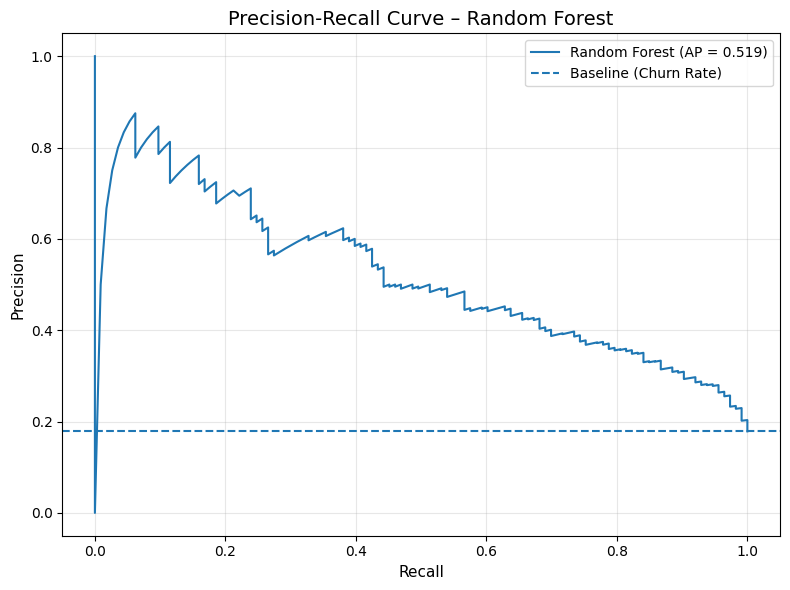

In [76]:
from sklearn.metrics import precision_recall_curve, average_precision_score

# Calculate precision-recall values
rf_precision, rf_recall, pr_thresholds = precision_recall_curve(
    y_test,
    rf_test_probabilities
    )
rf_avg_precision = average_precision_score(
      y_test,
      rf_test_probabilities
      )
plt.figure(figsize=(8, 6))

plt.plot(
    rf_recall,
    rf_precision,
    label=f"Random Forest (AP = {rf_avg_precision:.3f})"
    )
plt.axhline(
      y_test.mean(),
      linestyle="--",
      label="Baseline (Churn Rate)"
      )
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve – Random Forest")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [77]:
validation_comparison = pd.DataFrame([
      {
          "Model": "Logistic Regression",
          "Best Threshold": 0.50,
          "Precision": 0.362,
          "Recall": 0.832,
          "F1 Score": 0.504
          },
           {
               "Model": "Random Forest",
               "Best Threshold": 0.40,
               "Precision": 0.367,
               "Recall": 0.858,
               "F1 Score": 0.515
               },
                {
                    "Model": "Gradient Boosting",
                    "Best Threshold": 0.30,
                    "Precision": 0.449,
                     "Recall": 0.425,
                     "F1 Score": 0.436
                  },
                   {
                       "Model": "HistGradientBoosting",
                        "Best Threshold": 0.30,
                         "Precision": 0.468,
                          "Recall": 0.522,
                          "F1 Score": 0.494
                       }
      ])
test_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Threshold": 0.50,
        "Accuracy": 0.703,
        "Precision": 0.352,
        "Recall": 0.788,
        "F1 Score": 0.486,
        "ROC-AUC": 0.819,
        "Average Precision": None
        },
         {
             "Model": "Random Forest",
             "Threshold": 0.40,
             "Accuracy": 0.701,
             "Precision": 0.354,
            "Recall": 0.814,
             "F1 Score": 0.493,
           "ROC-AUC": 0.827,
          "Average Precision": rf_avg_precision
             }
    ])

print("VALIDATION MODEL COMPARISON")
display(validation_comparison.round(3))

print("FINAL TEST SET EVALUATION")
display(test_comparison.round(3))

validation_comparison.to_csv(
     "validation_model_comparison.csv", index=False
     )
test_comparison.to_csv(
      "final_test_model_comparison.csv", index=False
      )
print("Both evaluation tables exported successfully!")

VALIDATION MODEL COMPARISON


,Model,Best Threshold,Precision,Recall,F1 Score
0,Logistic Regression,0.5,0.362,0.832,0.504
1,Random Forest,0.4,0.367,0.858,0.515
2,Gradient Boosting,0.3,0.449,0.425,0.436
3,HistGradientBoosting,0.3,0.468,0.522,0.494


FINAL TEST SET EVALUATION


,Model,Threshold,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Average Precision
0,Logistic Regression,0.5,0.703,0.352,0.788,0.486,0.819,NaN
1,Random Forest,0.4,0.701,0.354,0.814,0.493,0.827,0.519


Both evaluation tables exported successfully!


# Exporting Results for Tableau

In [78]:
import os

base_path = '/content/drive/MyDrive/Peloton_Churn_Project/'

exports = {
    "business_insights.csv": "business_insights",
     "plan_churn.csv": "plan_churn",
     "tier_churn.csv": "tier_churn",
     "channel_churn.csv": "channel_churn",
      "cancellation_analysis.csv": "cancellation_analysis",
      "device_churn.csv": "device_churn",
      "engagement_comparison.csv": "engagement_comparison",
       "age_churn.csv": "age_churn",
       "validation_model_comparison.csv": "validation_comparison",
        "final_test_model_comparison.csv": "test_comparison"
        }

os.makedirs(base_path, exist_ok=True)

exported = []
missing = []

for filename, variable_name in exports.items():
  if variable_name in globals():
    df = globals()[variable_name]
    if isinstance(df, pd.DataFrame):
       df.to_csv(os.path.join(base_path, filename), index=False)
       exported.append(filename)
    else:
      missing.append(filename)
  else:
    missing.append(filename)

print("Successfully exported:")
for filename in exported:
    print("✓", filename)

print("\nNot found in the current session:")
for filename in missing:
  print("✗", filename)


Successfully exported:
✓ business_insights.csv
✓ plan_churn.csv
✓ tier_churn.csv
✓ channel_churn.csv
✓ cancellation_analysis.csv
✓ device_churn.csv
✓ engagement_comparison.csv
✓ age_churn.csv
✓ validation_model_comparison.csv
✓ final_test_model_comparison.csv

Not found in the current session:


In [79]:

import pandas as pd
import os
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    confusion_matrix
            )
export_path = "/content/drive/MyDrive/Peloton_Churn_Project/"
os.makedirs(export_path, exist_ok=True)

# Actual test labels
y_actual = pd.Series(y_test).reset_index(drop=True)

# Random Forest test probabilities
y_scores = pd.Series(rf_test_probabilities).reset_index(drop=True)

# Selected threshold
threshold = RF_FINAL_THRESHOLD

# 1. ROC Curve
fpr, tpr, roc_thresholds = roc_curve(y_actual, y_scores)

roc_df = pd.DataFrame({
    "False Positive Rate": fpr,
    "True Positive Rate": tpr,
    "Threshold": roc_thresholds
    })
roc_df.to_csv(export_path + "roc_curve_data.csv", index=False)

# 2. Precision-Recall Curve
precision, recall, pr_thresholds = precision_recall_curve(
    y_actual, y_scores
    )

pr_df = pd.DataFrame({
    "Precision": precision,
    "Recall": recall
    })

pr_df.to_csv(
    export_path + "precision_recall_data.csv",
    index=False
    )

# 3. Confusion Matrix
cm = confusion_matrix(
     y_actual,
     rf_test_predictions,
     labels=[0, 1]
     )

cm_df = pd.DataFrame(
    cm,
    index=["Actual No Churn", "Actual Churn"],
    columns=["Predicted No Churn", "Predicted Churn"]
    )

cm_df.to_csv(export_path + "confusion_matrix.csv")

print("Successfully exported:")
print("✓ roc_curve_data.csv")
print("✓ precision_recall_data.csv")
print("✓ confusion_matrix.csv")

print("\nConfusion Matrix:")
display(cm_df)

Successfully exported:
✓ roc_curve_data.csv
✓ precision_recall_data.csv
✓ confusion_matrix.csv

Confusion Matrix:


,Predicted No Churn,Predicted Churn
Actual No Churn,352,168
Actual Churn,21,92


In [80]:
confusion_df = pd.DataFrame(
      confusion_matrix(y_test, rf_test_predictions, labels=[0, 1]),
          columns=["Predicted No Churn", "Predicted Churn"]
          )

confusion_df.insert(
              0, "Actual",
                  ["Actual No Churn", "Actual Churn"]
                  )

confusion_df.to_csv(
                      "/content/drive/MyDrive/Peloton_Churn_Project/confusion_matrix.csv",
                          index=False
                          )

display(confusion_df)


,Actual,Predicted No Churn,Predicted Churn
0,Actual No Churn,352,168
1,Actual Churn,21,92


In [81]:
confusion_df.to_csv(
      "/content/drive/MyDrive/Peloton_Churn_Project/confusion_matrix_tableau.csv",
          index=False
          )

print("Export successful!")
display(confusion_df)


Export successful!


,Actual,Predicted No Churn,Predicted Churn
0,Actual No Churn,352,168
1,Actual Churn,21,92


In [82]:
feature_importance_df = pd.DataFrame({
      "Feature": X_val.columns,
          "Importance": rf_permutation.importances_mean,
              "Std": rf_permutation.importances_std
              })


feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
                  )

feature_importance_df.to_csv(
    "/content/drive/MyDrive/Peloton_Churn_Project/feature_importance.csv",
    index=False
                          )

display(feature_importance_df)


,Feature,Importance,Std
0,plan_type,0.188460,0.026036
6,workouts_completed,0.029752,0.012484
7,minutes_active,0.024784,0.014989
8,classes_booked,0.008956,0.011498
2,monthly_price,0.007927,0.017259
4,primary_device,0.003017,0.005978
3,acquisition_channel,-0.000059,0.010634
9,support_tickets,-0.002243,0.001919
5,age_group,-0.008102,0.011069
1,plan_tier,-0.011513,0.006954


In [83]:
feature_importance_df.to_csv(
      "/content/drive/MyDrive/Peloton_Churn_Project/feature_importance.csv",
          index=False
          )

print("Feature importance CSV exported successfully!")


Feature importance CSV exported successfully!
